In [ ]:
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

# Question 2

In [ ]:
f = lambda x: 200*(x[1] - x[0]**2)**2 + (1 - x[0])**2
grad = lambda x: np.array([-800*(x[0]*x[1] - x[0]**3) - 2*(1 - x[0]), 
                           400*(x[1] - x[0]**2)])
hess = lambda x: np.array([[-800*(x[1] - 3*x[0]**2) + 2, -800*x[0]], 
                           [-800*x[0], 400]])

x_min = np.array([1, 1])

In [ ]:
def descend(x, update, T=10_000, **kwargs):
    distances = losses = np.array([])
    for _ in tqdm(range(T)):
        distances = np.append(distances, np.linalg.norm(x - x_min))
        losses = np.append(losses, f(x) - f(x_min))
        x = update(x, **kwargs)
    return distances, losses

In [ ]:
# Question 2a-2c
newton = lambda x: x - np.linalg.inv(hess(x)) @ grad(x)
gradient_descent = lambda x, mu: x - mu * grad(x)

def backtrack(x, gamma, beta):
    mu = 1
    norm = np.linalg.norm(grad(x))
    while f(x - mu*grad(x)) > f(x) - gamma*mu*norm**2:
        mu *= beta
    return x - mu * grad(x)

In [ ]:
# Question 2d
x0 = np.array([0, 0])
data = {"Newton": descend(x0, newton), 
        "Gradient Descent": descend(x0, gradient_descent, mu=1e-3), 
        "Backtracking": descend(x0, backtrack, gamma=0.8, beta=0.5)}

fig, ax = plt.subplots(2, 3, figsize=(18, 8))
for i, (name, (distances, losses)) in enumerate(data.items()):
    ax[0, i].plot(distances)
    ax[1, i].plot(losses)
    ax[0, i].set_title(f'{name} Distance')
    ax[1, i].set_title(f'{name} Loss')
    
plt.show()

# Question 3

In [91]:
train_data = pd.read_csv('data/mnist_train.csv', header=None)
train_data = train_data.rename(columns={0: 'label'})

label_map = {-1: 4, 1: 9}
train_df = pd.concat([(train_data.query(f'label == {num}').iloc[:500] / 255)
                      .assign(label=[label] * 500) 
                      for label, num in label_map.items()])
train_df.reset_index(drop=True)

X = train_df.iloc[:, 1:].to_numpy()
Y = train_df.iloc[:, 0].to_numpy()
w_0 = np.zeros(X.shape[1])

In [92]:
def F(w):
    log_reg = lambda w, x, y: np.log(1 + np.exp(-y * np.dot(x, w)))
    return np.mean([log_reg(w, x, y) for x, y in zip(X, Y)])

def grad(w):
    sigmoid = lambda z: 1 / (1 + np.exp(-np.clip(z, -500, 500)))
    log_reg_grad = lambda w, x, y: sigmoid(-y * np.dot(x, w)) * (-y * x)
    return np.mean([log_reg_grad(w, x, y) for x, y in zip(X, Y)], axis=0)

def train(w, update, T=10_000, **kwargs):
    losses = np.array([])
    last_w = 0
    for t in tqdm(np.arange(T)):
        losses = np.append(losses, F(w))
        
        temp = w
        w = update(w, last_w=last_w, **kwargs)
        last_w = temp
        
        tqdm.write(f'Step: {t+1}, Loss: {losses[-1]}', end='\r')
        
    plt.plot(losses)
    plt.title('Training Loss')
    plt.show()
    return w

In [93]:
def backtrack(w, gamma, beta, **_):
    mu = 1e-1
    norm = np.linalg.norm(grad(w))
    while F(w - mu*grad(w)) > F(w) - mu*gamma*norm**2:
        mu *= beta
    return w - mu * grad(w)

# w_bt = train(w_0, backtrack, gamma=0.5, beta=0.8)

  0%|          | 0/10000 [00:00<?, ?it/s]

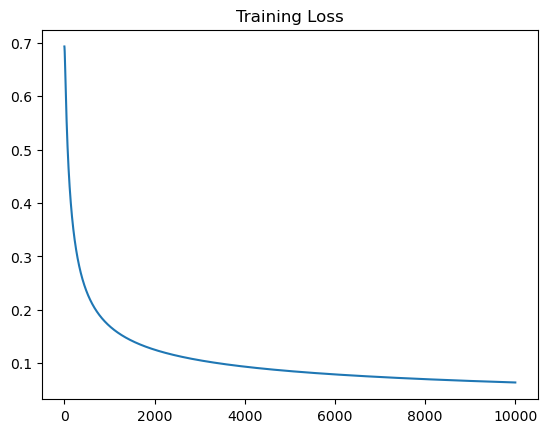

In [95]:
def momentum(w, last_w, mu, beta): 
    return w + beta*(w - last_w) - mu * grad(w)

w_m = train(w_0, momentum, mu=1e-3, beta=0.9)

  0%|          | 0/10000 [00:00<?, ?it/s]

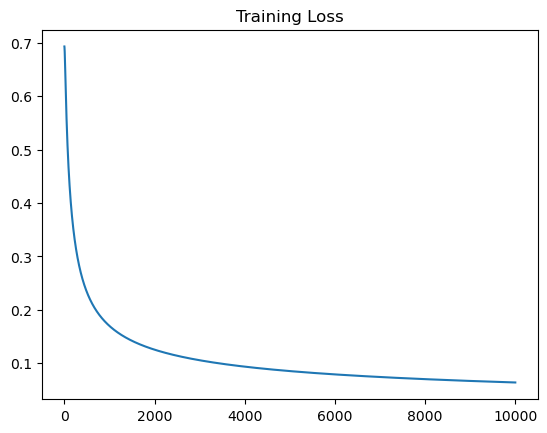

In [96]:
def nesterov(w, last_w, mu, beta):
    y = w + beta * (w - last_w)
    return y - mu * grad(y)

w_n = train(w_0, nesterov, mu=1e-3, beta=0.9)